In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt

from gensim.models import FastText
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

print("FastText imported successfully!")

FastText imported successfully!


In [3]:
sentences = [
    # Royalty and relationships
    "king queen prince princess royal kingdom palace",
    "the king rules the kingdom from his royal palace",
    "the queen is the wife of the king",
    "the prince is the son of the king and queen",
    "the princess is the daughter of the king and queen",
    "the king and queen live in the palace",
    "the prince and princess belong to the royal family",

    # Gender and people
    "man woman boy girl person people",
    "the man is strong and the woman is strong",
    "the boy is young and the girl is young",
    "the man is the father of the boy",
    "the woman is the mother of the girl",
    "a boy grows into a man",
    "a girl grows into a woman",

    # Countries, cities and languages
    "paris is the capital of france",
    "berlin is the capital of germany",
    "rome is the capital of italy",
    "france paris french europe",
    "germany berlin german europe",
    "italy rome italian europe",
    "people in france speak french",
    "people in germany speak german",
    "people in italy speak italian",
    "paris berlin and rome are european cities",

    # Animals and pets
    "cat dog animal pet puppy kitten",
    "a cat is a small domestic animal",
    "a kitten is a young cat",
    "a puppy is a young dog",
    "dogs and cats are popular pets",
    "a dog is a loyal animal",
    "a cat can be a friendly pet",
    "puppies and kittens are young animals",

    # Machine learning and artificial intelligence
    "machine learning is a branch of artificial intelligence",
    "artificial intelligence allows machines to perform intelligent tasks",
    "deep learning is a branch of machine learning",
    "neural networks are used in deep learning",
    "a neural network contains interconnected neurons",
    "machine learning models learn patterns from data",
    "deep learning models learn complex patterns",
    "training data is used to train machine learning models",
    "artificial neural networks are inspired by the human brain",
    "data science uses statistics and machine learning",
    "a trained model makes predictions on new data",
    "natural language processing helps computers understand text",
    "computer vision helps machines understand images",
    "deep learning is used in computer vision and natural language processing",
] * 100

print("Number of sentences:", len(sentences))

Number of sentences: 4600


In [4]:
def tokenize(text):
    return re.findall(r"\b[a-z]+\b", text.lower())

tokenized_sentences = [
    tokenize(sentence)
    for sentence in sentences
]

print("Example tokens:", tokenized_sentences[0])
print("Total sentences:", len(tokenized_sentences))

Example tokens: ['king', 'queen', 'prince', 'princess', 'royal', 'kingdom', 'palace']
Total sentences: 4600


In [5]:
fasttext_model = FastText(
    sentences=tokenized_sentences,
    vector_size=50,
    window=2,
    min_count=1,
    sg=1,
    min_n=3,
    max_n=6,
    workers=4,
    epochs=50,
    seed=42
)

fasttext_vectors = fasttext_model.wv

print("Vocabulary size:", len(fasttext_vectors))
print("Embedding dimensions:", fasttext_vectors.vector_size)

Vocabulary size: 117
Embedding dimensions: 50


In [6]:
word = "king"

vector = fasttext_vectors[word]

print("Word:", word)
print("Vector shape:", vector.shape)
print("First 10 values:", vector[:10])

Word: king
Vector shape: (50,)
First 10 values: [ 0.0653384   0.25867712  0.08627897  0.6783233  -0.15623318  0.4084242
  0.04085604  0.10337966  0.36658296 -0.13995957]


In [7]:
def word_similarity(word1, word2):
    return float(
        fasttext_vectors.similarity(word1, word2)
    )

pairs = [
    ("king", "queen"),
    ("king", "man"),
    ("paris", "france"),
    ("machine", "learning"),
    ("cat", "dog"),
]

for word1, word2 in pairs:
    print(
        f"{word1:10s} ↔ {word2:10s}: "
        f"{word_similarity(word1, word2):.4f}"
    )

king       ↔ queen     : 0.7193
king       ↔ man       : 0.2593
paris      ↔ france    : 0.5598
machine    ↔ learning  : 0.6526
cat        ↔ dog       : 0.5721


In [8]:
def most_similar(word, top_k=5):
    return fasttext_vectors.most_similar(
        word,
        topn=top_k
    )

for word in ["queen", "france", "machine", "german"]:
    print(f"\nNearest neighbors of '{word}':")

    for neighbor, score in most_similar(word, top_k=5):
        print(f"  {neighbor:15s} {score:.4f}")


Nearest neighbors of 'queen':
  king            0.7193
  prince          0.6505
  son             0.6477
  palace          0.6427
  daughter        0.6171

Nearest neighbors of 'france':
  french          0.7661
  italy           0.6850
  germany         0.6715
  science         0.6700
  german          0.5854

Nearest neighbors of 'machine':
  machines        0.7014
  learning        0.6526
  data            0.5965
  science         0.5924
  complex         0.5858

Nearest neighbors of 'german':
  germany         0.8706
  italian         0.7005
  french          0.6808
  man             0.6532
  human           0.6264


In [9]:
# Test FastText's special feature: unseen words
test_words = [
    "king",
    "kingdom",
    "kingdoms",
    "princess",
    "princesses",
    "computer",
    "computers"
]

for word in test_words:
    print(
        f"{word:15s}",
        "In vocabulary:", word in fasttext_vectors,
        "| Vector shape:", fasttext_vectors[word].shape
    )

king            In vocabulary: True | Vector shape: (50,)
kingdom         In vocabulary: True | Vector shape: (50,)
kingdoms        In vocabulary: True | Vector shape: (50,)
princess        In vocabulary: True | Vector shape: (50,)
princesses      In vocabulary: True | Vector shape: (50,)
computer        In vocabulary: True | Vector shape: (50,)
computers       In vocabulary: True | Vector shape: (50,)


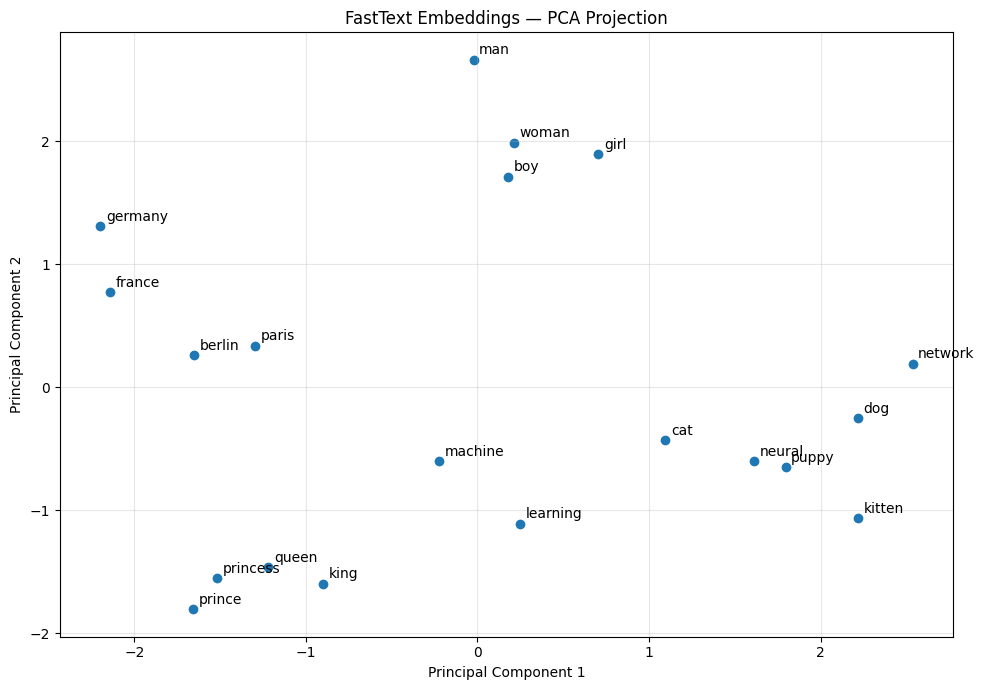

In [10]:
words_to_plot = [
    "king", "queen", "prince", "princess",
    "man", "woman", "boy", "girl",
    "paris", "france", "berlin", "germany",
    "cat", "dog", "puppy", "kitten",
    "machine", "learning", "neural", "network"
]

vectors = np.stack([
    fasttext_vectors[word]
    for word in words_to_plot
])

points_2d = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(10, 7))
plt.scatter(points_2d[:, 0], points_2d[:, 1])

for i, word in enumerate(words_to_plot):
    plt.annotate(
        word,
        (points_2d[i, 0], points_2d[i, 1]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("FastText Embeddings — PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()